In [41]:
import pandas as pd
import pandas_ta as ta
from plot.Plot import StockPlot

In [42]:
df = pd.read_csv('./data/world/DJI_2024-09-15_2024-11-14_1h.csv', index_col='Datetime', parse_dates=True)

plot_field='Close'

rsi = ta.rsi(df[plot_field], length=14)
ema = ta.ema(df[plot_field], length=14)
macd = ta.macd(df[plot_field], slow=12, fast=26, signal=9)

df["RSI"] = rsi
df["EMA"] = ema
df["MACD"] = macd["MACD_12_26_9"]
df["MACD_S"] = macd["MACD_12_26_9"]
df["MACD_H"] = macd["MACD_12_26_9"]

df = df.dropna()

# df.info

# print(data.index)  # Should show DatetimeIndex


In [43]:
df = df[df["Volume"] > 0]

# df

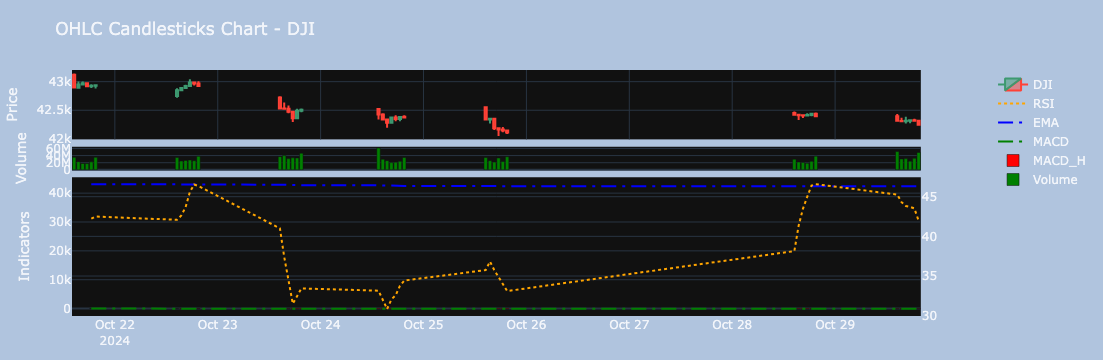

In [44]:
# Define indicators to plot
indicators = {
    # modes: ['lines', 'markers', 'lines+markers', 'text']
    'RSI': {'column': 'RSI', 'color': 'orange', 'mode': 'lines', 'dash': 'dot', 'type': 'scatter', 'secondary_y': True, 'smooth': True},
    'EMA': {'column': 'EMA', 'color': 'blue', 'mode': 'lines', 'dash': 'longdashdot', 'type': 'scatter', 'secondary_y': False, 'smooth': True},
    'MACD': {'column': 'MACD', 'color': 'green', 'mode': 'lines', 'dash': 'longdashdot', 'type': 'scatter', 'secondary_y': False, 'smooth': True},
    'MACD_H': {'column': 'MACD_H', 'color': 'red', 'type': 'bar', 'secondary_y': False, 'smooth': True},
}

# Plot data
plotter = StockPlot(df, indicators)
plotter.plot_data(plot_field=plot_field, start_date="2024-10-20", days=10)

In [45]:
trades = []
trade_value = 100
current_trade = {}
rsi_upper_threshold = 60
rsi_lower_threshold = 50

In [46]:
for i in range(len(df) - 1):
    print(f"Index {i}, RSI: {df.iloc[i].RSI}")
    print(f"RSI < 40: {df.iloc[i].RSI < rsi_lower_threshold}, RSI > 60: {df.iloc[i].RSI > rsi_upper_threshold}")
    if df.iloc[i].RSI > rsi_upper_threshold and len(current_trade) != 0:
        print(f"Sell signal at index {i}, RSI: {df.iloc[i].RSI}")
    elif df.iloc[i].RSI < rsi_lower_threshold and len(current_trade) == 0:
        print(f"Buy signal at index {i}, RSI: {df.iloc[i].RSI}")
    else:
        print(f"No signal at index {i}")


Index 0, RSI: 59.53752541565195
RSI < 40: False, RSI > 60: False
No signal at index 0
Index 1, RSI: 60.11090499030117
RSI < 40: False, RSI > 60: True
No signal at index 1
Index 2, RSI: 62.29521685987803
RSI < 40: False, RSI > 60: True
No signal at index 2
Index 3, RSI: 59.43911701841944
RSI < 40: False, RSI > 60: False
No signal at index 3
Index 4, RSI: 60.48231792710747
RSI < 40: False, RSI > 60: True
No signal at index 4
Index 5, RSI: 62.346313452002235
RSI < 40: False, RSI > 60: True
No signal at index 5
Index 6, RSI: 60.72572339649701
RSI < 40: False, RSI > 60: True
No signal at index 6
Index 7, RSI: 61.08549950717415
RSI < 40: False, RSI > 60: True
No signal at index 7
Index 8, RSI: 62.29867699809951
RSI < 40: False, RSI > 60: True
No signal at index 8
Index 9, RSI: 65.65586053039146
RSI < 40: False, RSI > 60: True
No signal at index 9
Index 10, RSI: 57.352973097976076
RSI < 40: False, RSI > 60: False
No signal at index 10
Index 11, RSI: 58.347308477493165
RSI < 40: False, RSI > 6

In [47]:
# Backtester
for i in range(len(df) -1):
    # print(f"current_trade: {len(current_trade)}")
    # print(f"Open: { df.iloc[i+1].Open }")
    # print(f"Name: { df.iloc[i+1].name }")
    # print(f"Rsi: { df.iloc[i].RSI } : { df.iloc[i].RSI < 30 }")
    if df.iloc[i].RSI > rsi_upper_threshold and len(current_trade) != 0: 
        # print(f"I: {i}: {df.iloc[i].RSI} is > 70")
        trades.append({
            "entry_price":current_trade["entry_price"],
            "entry_time":current_trade["entry_time"],
            "trade_size":current_trade["remaining_size"],
            "exit_price":df.iloc[i+1].Open,
            "exit_time":df.iloc[i+1].name,
            "profit_pct":(df.iloc[i+1].Open / current_trade["entry_price"]) -1,
        })
        current_trade = {}
    elif df.iloc[i].RSI < rsi_lower_threshold and len(current_trade) == 0:
        # print(f"I: {i}: {df.iloc[i].RSI} is < 30")
        current_trade["entry_price"] = df.iloc[i+1].Open
        current_trade["entry_time"] = df.iloc[i+1].name
        current_trade["initial_size"] = trade_value / current_trade["entry_price"]
        current_trade["remaining_size"] = current_trade["initial_size"]
        # print(len(current_trade))
    else:
        print(f"{i}: No signal found")

0: No signal found
1: No signal found
2: No signal found
3: No signal found
4: No signal found
5: No signal found
6: No signal found
7: No signal found
8: No signal found
9: No signal found
10: No signal found
11: No signal found
12: No signal found
13: No signal found
14: No signal found
16: No signal found
17: No signal found
18: No signal found
19: No signal found
20: No signal found
21: No signal found
22: No signal found
23: No signal found
24: No signal found
25: No signal found
26: No signal found
28: No signal found
29: No signal found
30: No signal found
31: No signal found
32: No signal found
34: No signal found
35: No signal found
36: No signal found
37: No signal found
38: No signal found
39: No signal found
40: No signal found
41: No signal found
42: No signal found
43: No signal found
44: No signal found
45: No signal found
46: No signal found
47: No signal found
48: No signal found
49: No signal found
50: No signal found
51: No signal found
52: No signal found
53: No sig

In [48]:
trades = pd.DataFrame(trades)

trades

,entry_price,entry_time,trade_size,exit_price,exit_time,profit_pct
0,42020.519531,2024-09-25 15:30:00+00:00,0.002380,42617.718750,2024-09-27 15:30:00+00:00,0.014212
1,42193.660156,2024-09-30 15:30:00+00:00,0.002370,42226.000000,2024-10-07 14:30:00+00:00,0.000766
2,42105.449219,2024-10-07 16:30:00+00:00,0.002375,42347.121094,2024-10-09 15:30:00+00:00,0.005740
3,42761.570312,2024-10-15 19:30:00+00:00,0.002339,42989.308594,2024-10-16 16:30:00+00:00,0.005326
4,42895.101562,2024-10-21 15:30:00+00:00,0.002331,43532.269531,2024-11-06 16:30:00+00:00,0.014854


In [49]:
# Ensure DatetimeIndex is timezone-aware (e.g., UTC)
# df.index = data.index.tz_localize('UTC')
df

,index,Open,High,Low,Close,Adj Close,Volume,Ticker,RSI,EMA,MACD,MACD_S,MACD_H
Datetime,,,,,,,,,,,,,
2024-09-20 18:30:00+00:00,33,41962.878906,42073.750000,41925.898438,42044.871094,42044.871094,95642704,DJI,59.537525,41955.382098,116.834588,116.834588,116.834588
2024-09-20 19:30:00+00:00,34,42044.820312,42132.839844,42030.179688,42059.500000,42059.500000,144628085,DJI,60.110905,41969.264485,116.486299,116.486299,116.486299
2024-09-23 14:30:00+00:00,36,42120.390625,42142.851562,42060.089844,42117.441406,42117.441406,53043258,DJI,62.295217,42006.501123,120.703909,120.703909,120.703909
2024-09-23 15:30:00+00:00,37,42117.449219,42129.398438,42035.871094,42075.058594,42075.058594,35727850,DJI,59.439117,42015.642119,116.691214,116.691214,116.691214
2024-09-23 16:30:00+00:00,38,42074.828125,42099.500000,42036.160156,42097.718750,42097.718750,33123284,DJI,60.482318,42026.585670,114.025198,114.025198,114.025198
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-13 16:30:00+00:00,296,44087.648438,44135.160156,44062.308594,44088.308594,44088.308594,48324377,DJI,57.964374,44058.167870,112.267775,112.267775,112.267775
2024-11-13 17:30:00+00:00,297,44088.601562,44141.328125,44053.429688,44075.011719,44075.011719,40435993,DJI,57.174666,44060.413716,105.083268,105.083268,105.083268
2024-11-13 18:30:00+00:00,298,44075.859375,44090.031250,43982.121094,43999.328125,43999.328125,41551188,DJI,52.767971,44052.268971,92.219412,92.219412,92.219412


In [50]:
# print(df.index)  # Ensure this shows DatetimeIndex
# print(df.index.dtype)  # Check for timezone awareness

df = df.dropna()

df = df[df["Volume"] > 0]

df

,index,Open,High,Low,Close,Adj Close,Volume,Ticker,RSI,EMA,MACD,MACD_S,MACD_H
Datetime,,,,,,,,,,,,,
2024-09-20 18:30:00+00:00,33,41962.878906,42073.750000,41925.898438,42044.871094,42044.871094,95642704,DJI,59.537525,41955.382098,116.834588,116.834588,116.834588
2024-09-20 19:30:00+00:00,34,42044.820312,42132.839844,42030.179688,42059.500000,42059.500000,144628085,DJI,60.110905,41969.264485,116.486299,116.486299,116.486299
2024-09-23 14:30:00+00:00,36,42120.390625,42142.851562,42060.089844,42117.441406,42117.441406,53043258,DJI,62.295217,42006.501123,120.703909,120.703909,120.703909
2024-09-23 15:30:00+00:00,37,42117.449219,42129.398438,42035.871094,42075.058594,42075.058594,35727850,DJI,59.439117,42015.642119,116.691214,116.691214,116.691214
2024-09-23 16:30:00+00:00,38,42074.828125,42099.500000,42036.160156,42097.718750,42097.718750,33123284,DJI,60.482318,42026.585670,114.025198,114.025198,114.025198
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-13 16:30:00+00:00,296,44087.648438,44135.160156,44062.308594,44088.308594,44088.308594,48324377,DJI,57.964374,44058.167870,112.267775,112.267775,112.267775
2024-11-13 17:30:00+00:00,297,44088.601562,44141.328125,44053.429688,44075.011719,44075.011719,40435993,DJI,57.174666,44060.413716,105.083268,105.083268,105.083268
2024-11-13 18:30:00+00:00,298,44075.859375,44090.031250,43982.121094,43999.328125,43999.328125,41551188,DJI,52.767971,44052.268971,92.219412,92.219412,92.219412


In [61]:
import numpy as np
import pandas as pd
import pandas_ta as ta
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from mplfinance.original_flavor import candlestick_ohlc

class StockPlot2:
    def __init__(self, data, calculation_field="Close", indicators={}):
        self.df = data  
        self.indicators = indicators 
        self.tickers = self.df['Ticker'].unique()
        self.calculation_field = calculation_field

    def _filter_data(self, ticker_data, target_date=None, days=5):
        """Filter the data to include rows starting from a specific date."""
        if not pd.api.types.is_datetime64_any_dtype(ticker_data.index):
            ticker_data.index = pd.to_datetime(ticker_data.index)
        if target_date:
            start_date = pd.to_datetime(target_date).normalize()
        else:
            start_date = ticker_data.index.max() - pd.Timedelta(days=days)
        end_date = start_date + pd.Timedelta(days=days)
        return ticker_data.loc[(ticker_data.index >= start_date) & (ticker_data.index < end_date)]
    
    def _calculate_indicator(self, ticker_data, column, length=None):
        """
        Dynamically calculate an indicator using the specified library (e.g., pandas_ta).
        
        Args:
            ticker_data (pd.DataFrame): The input DataFrame containing stock data.
            column (str): The name of the indicator to calculate.
            length (int): The window length for the indicator (if applicable).
        
        Returns:
            pd.DataFrame: The updated DataFrame with the calculated indicator,
                          cleaned to exclude None, NaN, or values < 0.
        """
        # Check if the column already exists
        if column in ticker_data.columns:
            print(f"Indicator '{column}' already exists in the dataset.")
            return ticker_data  # Return unmodified DataFrame if the column exists

        try:
            # Check if the library has the desired indicator function
            if hasattr(ta, column.lower()):
                indicator_func = getattr(ta, column.lower())  # Dynamically get the function
    
                # Handle MACD (multi-output indicator)
                if column.upper() == 'MACD':
                    macd_result = indicator_func(ticker_data[self.calculation_field])
                    if isinstance(macd_result, pd.DataFrame):  # Ensure output is a DataFrame
                        for col in macd_result.columns:  # Add all MACD components to the DataFrame
                            ticker_data[col] = macd_result[col]
                        ticker_data[column] = macd_result.iloc[:, 0]  # Assign the first column as 'MACD'
                    else:
                        raise ValueError(f"MACD calculation did not return a DataFrame for '{column}'.")
    
                # Handle other indicators
                else:
                    data = indicator_func(ticker_data[self.calculation_field], length=length)
                    if isinstance(data, pd.Series):
                        ticker_data[column] = data
                    else:
                        raise ValueError(f"Indicator '{column}' calculation did not return a Series.")
    
            else:
                print(f"Warning: Indicator '{column}' is not found in the pandas_ta library.")
                return ticker_data
    
        except Exception as e:
            print(f"Error calculating indicator '{column}': {e}")
            return ticker_data
    
        # Clean the DataFrame: Drop rows with NaN or invalid values for the new column
        ticker_data = ticker_data[ticker_data[column].notna()]  # Drop NaN
        ticker_data = ticker_data[ticker_data[column] >= 0]     # Drop values < 0
    
        return ticker_data
        
    def plot_data(self, title="", start_date=None, days=None):
        """Plot the stock data with candlestick and indicators."""
        ndf = self.df.copy()
    
        for ticker in self.tickers:
            ticker_data = ndf[ndf['Ticker'] == ticker].sort_index()
            if days:
                ticker_data = self._filter_data(ticker_data, start_date, days)
    
            # Convert date index to numerical format for candlestick
            ohlc = ticker_data.reset_index()
            ohlc['Datetime'] = mdates.date2num(ohlc['Datetime'])
            ohlc = ohlc[['Datetime', 'Open', 'High', 'Low', 'Close']]
    
            # Create subplots
            fig, axs = plt.subplots(
                nrows=3, ncols=1, figsize=(12, 8), gridspec_kw={'height_ratios': [3, 1, 2]}
            )
            fig.suptitle(f"{ticker} - {title}", fontsize=16)
    
            # Plot candlestick chart
            ax1 = axs[0]
            candlestick_ohlc(ax1, ohlc.values, width=0.6, colorup='green', colordown='red', alpha=0.8)
            ax1.set_title("Candlestick Chart")
            ax1.xaxis_date()
            ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
            ax1.grid(True)
    
            # Plot volume
            ax2 = axs[1]
            ax2.bar(ticker_data.index, ticker_data['Volume'], color='blue', alpha=0.6)
            ax2.set_title("Volume")
            ax2.grid(True)
    
            # Plot indicators
            ax3 = axs[2]
            for indicator, details in self.indicators.items():
                column = details.get('column')
                color = details.get('color', 'blue')
                smooth = details.get('smooth', True)
                ind_type = details.get('ind_type', 'plot')
                smoothing_window = details.get('smoothing_window', 5)
    
                # Calculate or retrieve the indicator dynamically
                if column not in ticker_data.columns:
                    ticker_data = self._calculate_indicator(
                        ticker_data, column=column, length=smoothing_window
                    )
    
                data = ticker_data[column]
    
                # Ensure data is 1D and aligns with ticker_data.index
                if len(data) != len(ticker_data.index):
                    print(f"Aligning index and data for '{column}': lengths {len(ticker_data.index)} and {len(data)}.")
                    data = data.reindex(ticker_data.index)
    
                data = data.dropna()  # Clean data
                ticker_data = ticker_data.dropna(subset=[column])  # Ensure alignment
    
                # Plot the indicator
                if ind_type == 'bar':
                    ax3.bar(ticker_data.index, data, label=indicator, color=color, alpha=0.6)
                else:
                    ax3.plot(ticker_data.index, data, label=indicator, color=color)
    
            ax3.set_title("Indicators")
            ax3.grid(True)
            ax3.legend()
    
            plt.tight_layout(rect=[0, 0, 1, 0.95])
            plt.show()


# Example usage
# Generate sample data
np.random.seed(42)
data = pd.DataFrame({
    'Datetime': pd.date_range(start='2024-09-16 13:30:00', periods=100, freq='h'),
    'Open': np.random.rand(100) * 100,
    'High': np.random.rand(100) * 100 + 10,
    'Low': np.random.rand(100) * 90,
    'Close': np.random.rand(100) * 100,
    'Volume': np.random.randint(1000, 5000, 100),
    'Ticker': ['AAPL'] * 100
})

# Assume data has the 'Close' column and a valid Datetime index
# data = pd.DataFrame({
#     'Datetime': pd.date_range(start='2024-09-16 13:30:00', periods=50, freq='H', tz='UTC'),
#     'Close': np.random.rand(50) * 100,
# })
data.set_index('Datetime',  inplace=True)


# data
calculation_field='Close'

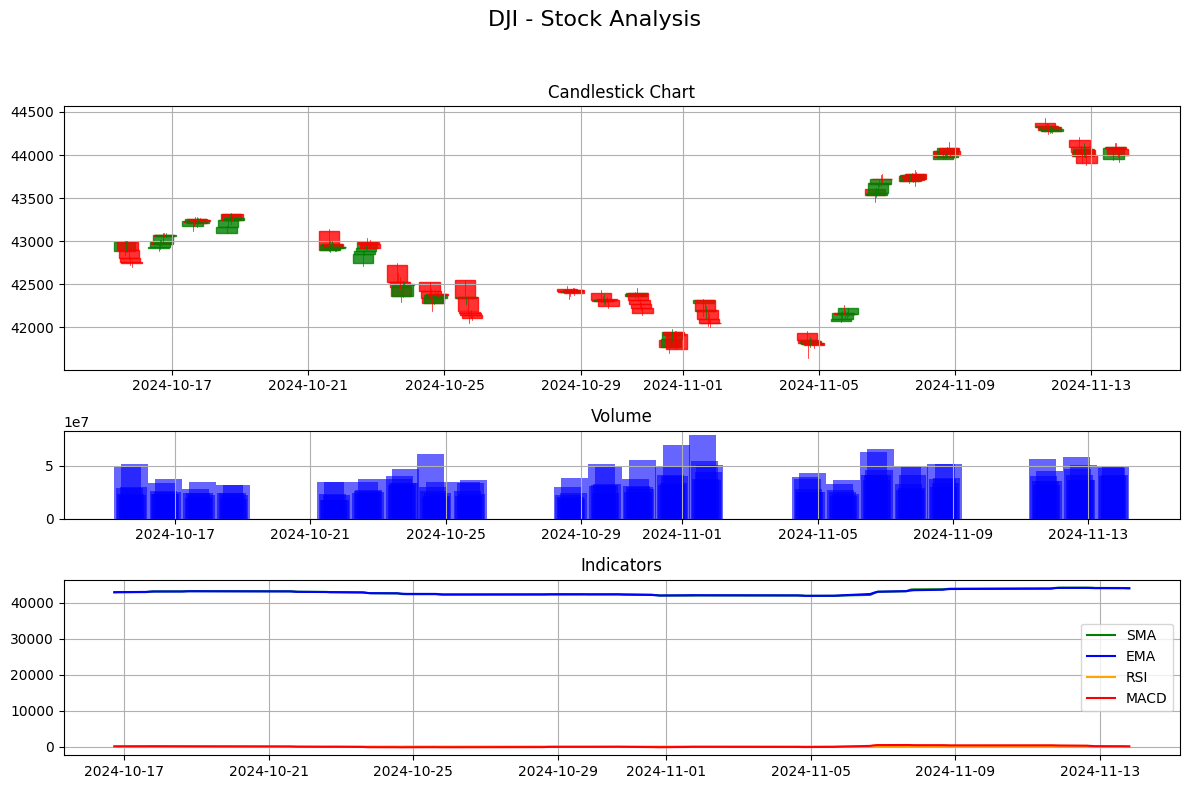

In [62]:
indicators = {
    'SMA': {'column': 'SMA', 'color': 'green', 'smooth': True, 'smoothing_window': 10},
    'EMA': {'column': 'EMA', 'color': 'blue', 'smooth': True, 'smoothing_window': 10},
    'RSI': {'column': 'RSI', 'color': 'orange', 'smooth': True,  'smoothing_window': 14},
    'MACD': {'column': 'MACD', 'color': 'red', 'smooth': True},
}

sp = StockPlot2(data=df, calculation_field="Close", indicators=indicators)
sp.plot_data(title="Stock Analysis", days=30)

Error calculating indicator 'EMA': Unexpected output format for indicator 'EMA' from pandas-ta.
Error calculating indicator 'MACD': Unexpected MACD format from pandas-ta for 'MACD'.


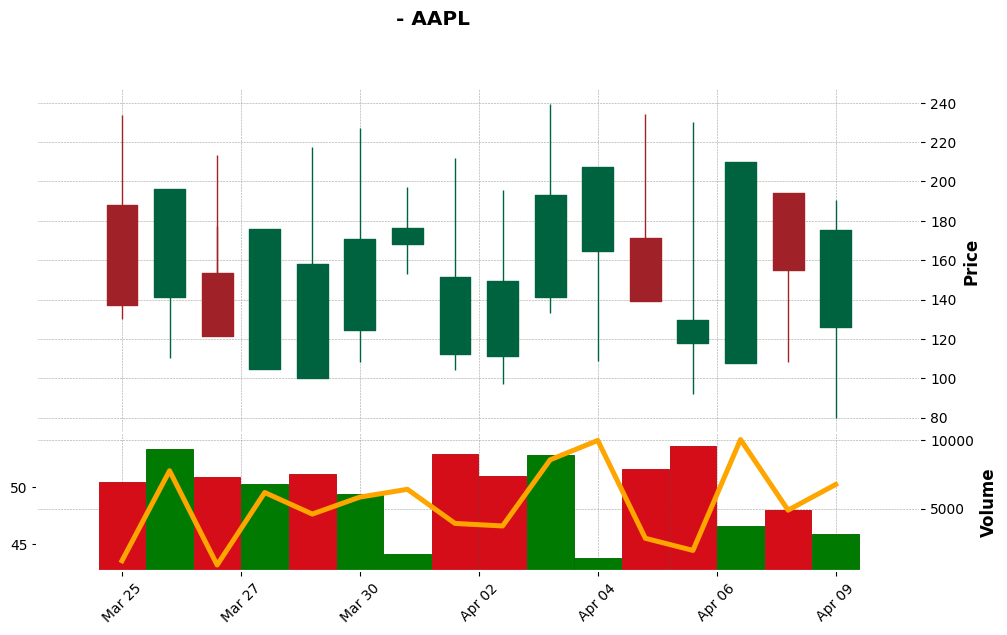

In [80]:
import pandas as pd
import numpy as np
import mplfinance as mpf
import pandas_ta as ta

try:
    import talib
except ImportError:
    talib = None

class StockPlotDynamicIndicators:
    def __init__(self, data, calculation_field = 'Close', indicators={}):
        """
        Initialize with stock data and indicator configurations.
        Args:
            data (pd.DataFrame): DataFrame with OHLCV data and optional Ticker column.
            indicators (dict): Dictionary with indicator configurations.
        """
        self.df = data
        self.indicators = indicators
        self.tickers = self.df['Ticker'].unique()
        self.calculation_field = calculation_field

    def _filter_data(self, ticker_data, target_date=None, days=5):
        """
        Filter the data to include rows starting from a specific date.
        """
        if not pd.api.types.is_datetime64_any_dtype(ticker_data.index):
            ticker_data.index = pd.to_datetime(ticker_data.index)

        if target_date:
            start_date = pd.to_datetime(target_date)
        else:
            start_date = ticker_data.index.max() - pd.Timedelta(days=days)

        end_date = start_date + pd.Timedelta(days=days)

        filtered_df = ticker_data.loc[(ticker_data.index >= start_date) & (ticker_data.index < end_date)]
        if filtered_df.empty:
            print("Warning: No data available in the specified range.")
        return filtered_df
    
    def _calculate_indicator(self, ticker_data, column, length=None):
        """
        Dynamically calculate an indicator using pandas-ta or ta-lib.
        
        Args:
            ticker_data (pd.DataFrame): The input DataFrame containing stock data.
            column (str): The name of the indicator to calculate (e.g., 'EMA', 'MACD').
            length (int): The window length for the indicator (if applicable).
        
        Returns:
            pd.DataFrame: The updated DataFrame with the calculated indicator added.
        """
        # Default calculation field
        calculation_field = getattr(self, 'calculation_field', 'Close')

        # Check if the indicator column already exists
        if column in ticker_data.columns:
            print(f"Indicator '{column}' already exists in the dataset.")
            return ticker_data
    
        try:
            # Handle pandas-ta
            if hasattr(ta, column.lower()):
                indicator_func = getattr(ta, column.lower())
                if column.upper() == 'MACD':
                    # pandas-ta MACD returns a DataFrame
                    result = indicator_func(ticker_data[calculation_field])
                    if isinstance(result, pd.DataFrame):
                        for sub_col in result.columns:
                            ticker_data[sub_col] = result[sub_col]
                    else:
                        raise ValueError(f"Unexpected MACD format from pandas-ta for '{column}'.")
                else:
                    # Handle single-output indicators like EMA
                    result = indicator_func(ticker_data[calculation_field], length=length)
                    if isinstance(result, pd.Series):
                        ticker_data[column] = result
                    else:
                        raise ValueError(f"Unexpected output format for indicator '{column}' from pandas-ta.")
    
            # Handle ta-lib
            elif talib and hasattr(talib, column.upper()):
                talib_func = getattr(talib, column.upper())
                if column.upper() == 'MACD':
                    # ta-lib MACD returns three arrays
                    macd, signal, hist = talib_func(
                        ticker_data[calculation_field].values,
                        fastperiod=12, slowperiod=26, signalperiod=9
                    )
                    ticker_data['MACD'] = macd
                    ticker_data['MACD_Signal'] = signal
                    ticker_data['MACD_Hist'] = hist
                else:
                    # Handle single-output indicators like EMA
                    result = talib_func(ticker_data[calculation_field].values, timeperiod=length)
                    ticker_data[column] = pd.Series(result, index=ticker_data.index)
    
            else:
                print(f"Warning: Indicator '{column}' is not found in pandas-ta or ta-lib.")
                return ticker_data
    
        except Exception as e:
            print(f"Error calculating indicator '{column}': {e}")
            return ticker_data
    
        # Clean up NaN or invalid values
        ticker_data[column] = ticker_data[column].replace([np.inf, -np.inf], np.nan)  # Replace infinities with NaN
        ticker_data.dropna(subset=[column], inplace=True)  # Drop rows with NaN in the indicator column
    
        return ticker_data
            
    def plot_data(self, plot_field="Close", title="", start_date=None, days=None, style='charles'):
        """
        Plot stock data with candlesticks, volume, and dynamically calculated indicators.
    
        Args:
            plot_field (str): The main field to plot (e.g., 'Close').
            title (str): Chart title.
            start_date (str): Start date for filtering data.
            days (int): Number of days to include in the plot.
            style (str): mplfinance style for the chart.
        """
        for ticker in self.tickers:
            ticker_data = self.df[self.df['Ticker'] == ticker].copy()
            ticker_data = ticker_data.sort_index()
    
            # Filter data for the date range
            if days:
                ticker_data = self._filter_data(ticker_data, start_date, days)
    
            # Skip if insufficient data
            if ticker_data.shape[0] < 10:
                print(f"Skipping {ticker}: Not enough data to plot.")
                continue
    
            # Calculate indicators
            for indicator, details in self.indicators.items():
                length = details.get('length', 14)
                ticker_data = self._calculate_indicator(ticker_data, indicator, length)
    
            # Prepare addplots for indicators
            add_plots = []
            for indicator, details in self.indicators.items():
                if indicator in ticker_data.columns:
                    color = details.get('color', 'blue')
                    panel = details.get('panel', 0)  # Default to main panel
                    add_plots.append(
                        mpf.make_addplot(ticker_data[indicator], color=color, panel=panel)
                    )
    
            # Plot the data with mplfinance
            mpf.plot(
                ticker_data,
                type='candle',
                volume=True,
                addplot=add_plots,
                title=f"{title} - {ticker}",
                style=style,
                ylabel='Price',
                ylabel_lower='Volume',
                figratio=(16, 9),
                figscale=1.2
            )

# Example Usage
# if __name__ == "__main__":
# Create sample data
data = pd.DataFrame({
    'Datetime': pd.date_range(start='2023-01-01', periods=100, freq='D'),
    'Open': np.random.uniform(100, 200, 100),
    'High': np.random.uniform(150, 250, 100),
    'Low': np.random.uniform(80, 180, 100),
    'Close': np.random.uniform(120, 220, 100),
    'Volume': np.random.randint(1000, 10000, 100),
    'Ticker': ['AAPL'] * 100,
})
data.set_index('Datetime', inplace=True)

# Define indicators
# Define indicators with details for plotting
indicators = {
    'RSI': {'length': 14, 'color': 'orange', 'panel': 1},
    'EMA': {'length': 20, 'color': 'green', 'panel': 0},
    'MACD': {'length': None, 'color': 'purple', 'panel': 2}
}

# Create and plot
stock_plot = StockPlotDynamicIndicators(data=data, indicators=indicators)
stock_plot.plot_data(days=30)

In [96]:
import warnings
import pandas as pd
import mplfinance as mpf

warnings.filterwarnings("ignore", category=FutureWarning)

class Utils:
    def __init__(self, data, calculation_field = 'Close', indicators={}):
        """
        Initialize with stock data and indicator configurations.
        Args:
            data (pd.DataFrame): DataFrame with OHLCV data and optional Ticker column.
            indicators (dict): Dictionary with indicator configurations.
        """
        self.df = data
        self.indicators = indicators
        self.tickers = self.df['Ticker'].unique()
        self.calculation_field = calculation_field

    def _filter_data(self, ticker_data, target_date=None, days=5):
        """
        Filter the data to include rows starting from a specific date.
        """
        if not pd.api.types.is_datetime64_any_dtype(ticker_data.index):
            ticker_data.index = pd.to_datetime(ticker_data.index)

        if target_date:
            start_date = pd.to_datetime(target_date)
        else:
            start_date = ticker_data.index.max() - pd.Timedelta(days=days)

        end_date = start_date + pd.Timedelta(days=days)

        filtered = ticker_data.loc[(ticker_data.index >= start_date) & (ticker_data.index < end_date)]
        if filtered.empty:
            print("Warning: No data available in the specified range.")
        
        return filtered
    
    def data_plot(self,  title="Candlestick Chart", start_date=None, days=None):
        """
        Plots a stock market style chart with candlesticks, indicators, and volume.
        Parameters:
            ohlc_cols (list): List of OHLC column names. Default is ['Open', 'High', 'Low', 'Close'].
            indicators (dict): Dictionary of indicators to plot with format {'indicator_name': column_name}.
            volume_col (str): Name of the volume column, if provided.
            title (str): Title of the plot.
            days (int): Number of most recent days to display. If None, show at least 6 months.
            start_date (str): Start date for generating data, in 'YYYY-MM-DD' format. If None, today's date will be used.
        """
        # Ensure you're working on a copy of the original DataFrame
        self.df = self.df.copy()

        for ticker in self.tickers:
            ticker_data = self.df[self.df['Ticker'] == ticker].copy()
            ticker_data = ticker_data.sort_index()
            
            # If 'days' is not provided, calculate it for 3 months (90 days)
            days = days if days is not None else 90            
            
            # Filter data for the date range
            if days:
                ticker_data = self._filter_data(ticker_data, start_date, days)
                # print(ticker_data.tail(2))

            # Skip if insufficient data
            # if ticker_data.shape[0] < 10:
            #     print(f"Skipping {ticker}: Not enough data to plot.")
            #     continue
        
            # Set start_date dynamically if None
            if start_date is None:
                start_date = pd.Timestamp.today().strftime('%Y-%m-%d')
            
            # Calculate the end date based on the start date and the number of days
            if start_date:
                end_date = pd.to_datetime(start_date) + pd.DateOffset(days=days-1)  # Subtract 1 because the start date counts as the first day
    
            # Title
            title = f"Stock Data Plting ( {start_date} <-> {end_date.strftime('%Y-%m-%d')} )"
            
            # # Generate the 'Datetime' column with the correct length based on filtered data
            # self.df.loc[:, 'Datetime'] = pd.date_range(start=start_date, periods=len(self.df), freq='D')
    
            # # Set the Datetime as the index
            # self.df.set_index('Datetime', inplace=True)
    
            # List to hold additional plots for indicators
            additional_plots = []
    
            # Create additional indicators
            # Loop through the provided indicators and add them if they exist in the dataframe
            # for indicator, details in indicators.items():
            #     column, color = details['column'], details['color']
                
            #     if column in self.df.columns:
            #         # Apply dynamic color logic (you can still modify this logic if needed)
            #         # We can keep it simple or use colors based on a condition like diff().
            #         colors = self.df[column].diff().apply(lambda x: color if x > 0 else 'red')
                    
            #         # Add the plot for this indicator with the provided color
            #         additional_plots.append(mpf.make_addplot(ticker_data[column], panel=0, color=colors, secondary_y=False))
            #     else:
            #         print(f"Warning: Indicator column '{column}' not found in the DataFrame.")
    
    
            # Define the market colors and style with ratio adjustments
            market_colors = mpf.make_marketcolors(up='green', down='red', inherit=True)
            
            # Adjusting figure ratio and size (not directly candle width)
            style = mpf.make_mpf_style(base_mpf_style='charles', marketcolors=market_colors)
    
            # Set the figure size and ratio
            fig_size = (14, 8)  # Size in inches
            figratio = (10, 6)  # Ratio of the figure
            
            # Plot the candlestick chart with volume and indicators
            mpf.plot(ticker_data, type='candle', style=style, title=title, volume=True, addplot=additional_plots, figsize=fig_size, figratio=figratio, xlabel="Datetime", ylabel="Price")


/Users/habib/Desktop/Projects/FinDRL/.venv/lib/python3.12/site-packages/mplfinance/plotting.py:707: UserWarning:

Attempting to set identical low and high ylims makes transformation singular; automatically expanding.



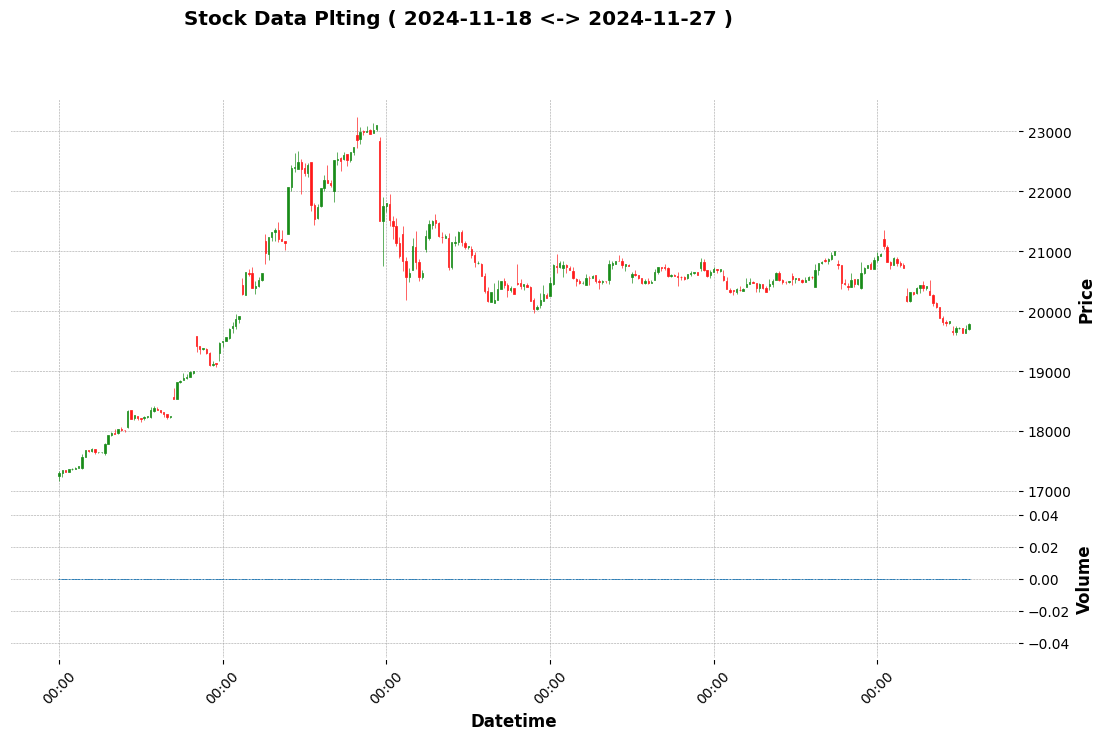

IndexError: index -1 is out of bounds for axis 0 with size 0

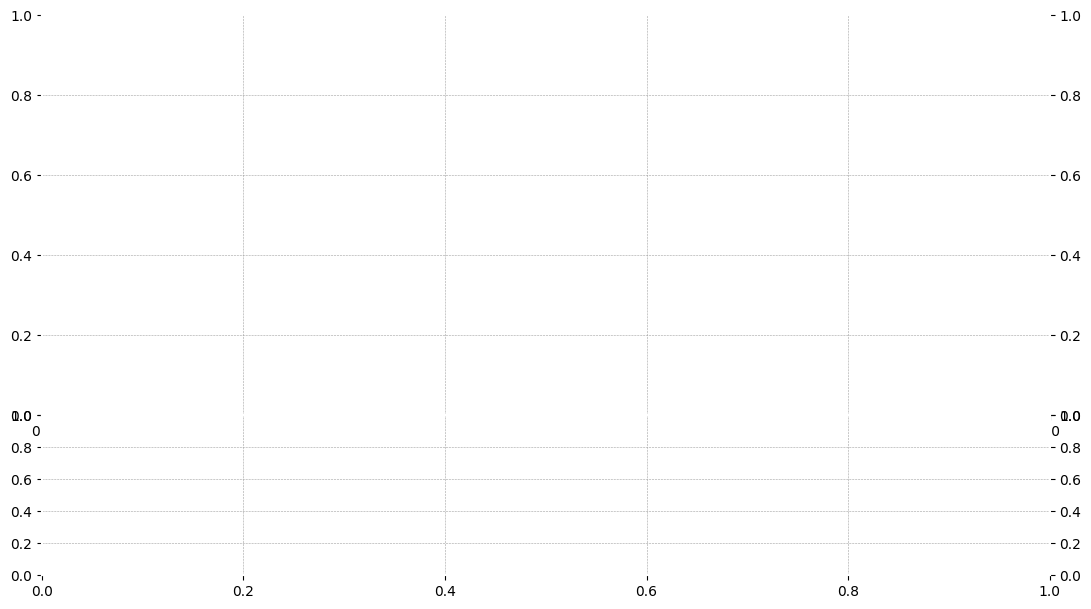

In [99]:
data = pd.read_csv('./data/world/processed.csv')

ploting = Utils(data)

ploting.data_plot(days=10)